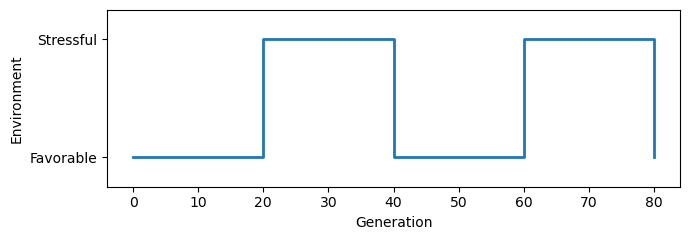

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tau_E = 20
t = np.arange(0, 4 * tau_E + 1)

# Alternate every tau_E generations
E = np.where((t // tau_E) % 2 == 0, -1, 1)

plt.figure(figsize=(7, 2.5))
plt.step(t, E, where="post", linewidth=2)

plt.yticks([-1, 1], ["Favorable", "Stressful"])
plt.xlabel("Generation")
plt.ylabel("Environment")
plt.ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()

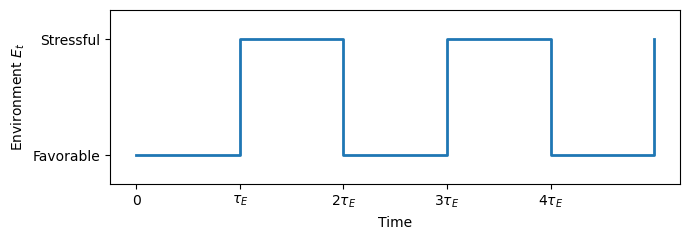

In [7]:

t = np.array([0, 1, 2, 3, 4, 5])
E = np.array([-1, 1, -1, 1, -1, 1])

plt.figure(figsize=(7, 2.5))
plt.step(t, E, where="post", linewidth=2)

plt.yticks([-1, 1], ["Favorable", "Stressful"])
plt.xticks(
    [0, 1, 2, 3, 4],
    ["0", r"$\tau_E$", r"$2\tau_E$", r"$3\tau_E$", r"$4\tau_E$"]
)

plt.xlabel("Time")
plt.ylabel(r"Environment $E_t$")
plt.ylim(-1.5, 1.5)

plt.tight_layout()
plt.savefig("fluctuating_environment.png", dpi=300, bbox_inches="tight")

plt.show()

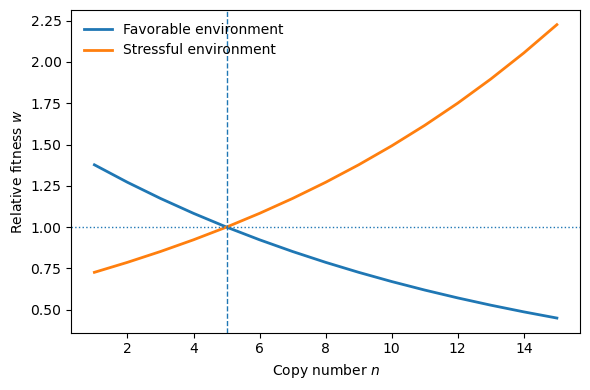

In [8]:

# Parameters
n0 = 5                  # reference copy number
s_fav = 0.08            # selection strength in favorable environment
s_stress = 0.08         # selection strength in stressful environment

# Copy-number values shown only for visualization
n = np.arange(1, 16)

# Fitness functions
w_fav = np.exp(-s_fav * (n - n0))
w_stress = np.exp(s_stress * (n - n0))

# Plot
plt.figure(figsize=(6, 4))

plt.plot(n, w_fav, linewidth=2, label="Favorable environment")
plt.plot(n, w_stress, linewidth=2, label="Stressful environment")

# Reference CN
plt.axvline(n0, linestyle="--", linewidth=1)
plt.axhline(1, linestyle=":", linewidth=1)

plt.xlabel("Copy number $n$")
plt.ylabel("Relative fitness $w$")
plt.legend(frameon=False)

plt.tight_layout()

plt.savefig("CN_fitness_environment.pdf", bbox_inches="tight")
plt.savefig("CN_fitness_environment.png", dpi=300, bbox_inches="tight")

plt.show()

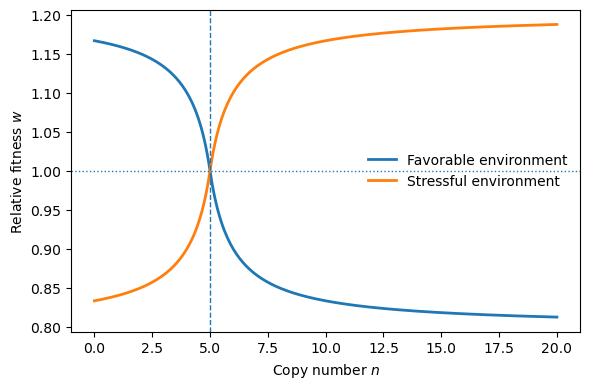

In [9]:

# Parameters
n0 = 5
s_fav = -0.2
s_stress = 0.2

# CN values just for visualization
n = np.linspace(0, 20, 300)

def fitness(n, s, n0):
    return 1 + s * (n - n0) / (1 + np.abs(n - n0))

w_fav = fitness(n, s_fav, n0)
w_stress = fitness(n, s_stress, n0)

plt.figure(figsize=(6, 4))

plt.plot(n, w_fav, linewidth=2, label="Favorable environment")
plt.plot(n, w_stress, linewidth=2, label="Stressful environment")

plt.axvline(n0, linestyle="--", linewidth=1)
plt.axhline(1, linestyle=":", linewidth=1)

plt.xlabel("Copy number $n$")
plt.ylabel("Relative fitness $w$")
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig("CN_fitness_bounded.pdf", bbox_inches="tight")
plt.savefig("CN_fitness_bounded.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
pip install networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


/tmp/ipykernel_444561/1260581052.py:19: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


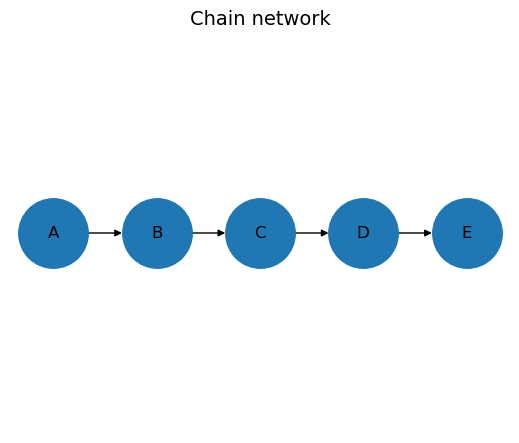

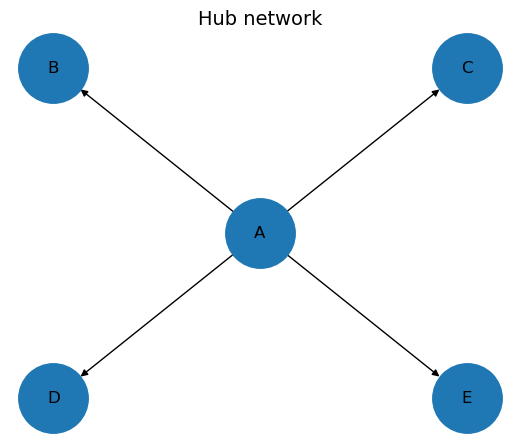

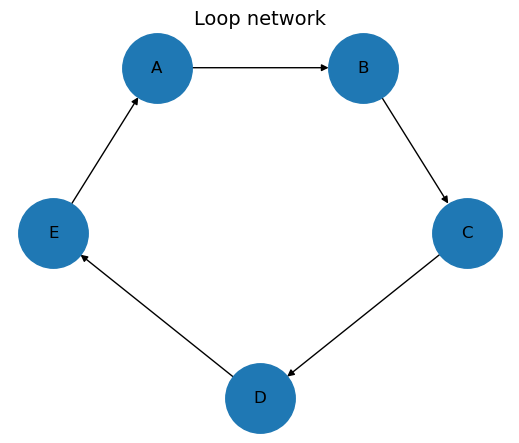

In [12]:
import matplotlib.pyplot as plt
import networkx as nx


def draw_network(edges, pos, title, filename):
    G = nx.DiGraph()
    G.add_edges_from(edges)

    plt.figure(figsize=(5, 4))
    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=2500,
        font_size=12,
        arrows=True
    )
    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()


# ---------- 1. Chain network ----------
chain_edges = [
    ("A", "B"),
    ("B", "C"),
    ("C", "D"),
    ("D", "E")
]

chain_pos = {
    "A": (0, 0),
    "B": (1, 0),
    "C": (2, 0),
    "D": (3, 0),
    "E": (4, 0)
}

draw_network(chain_edges, chain_pos, "Chain network", "chain_network.png")


# ---------- 2. Hub network ----------
hub_edges = [
    ("A", "B"),
    ("A", "C"),
    ("A", "D"),
    ("A", "E")
]

hub_pos = {
    "A": (0, 0),
    "B": (-1, 1),
    "C": (1, 1),
    "D": (-1, -1),
    "E": (1, -1)
}

draw_network(hub_edges, hub_pos, "Hub network", "hub_network.png")


# ---------- 3. Loop network ----------
loop_edges = [
    ("A", "B"),
    ("B", "C"),
    ("C", "D"),
    ("D", "E"),
    ("E", "A")
]

loop_pos = {
    "A": (0, 1),
    "B": (1, 1),
    "C": (1.5, 0),
    "D": (0.5, -1),
    "E": (-0.5, 0)
}

draw_network(loop_edges, loop_pos, "Loop network", "loop_network.png")